# **Super-Resolution of Historical Maps using ESRGAN**

*Jun 2025*

---

## **Abstract**  
Many online archives store historical maps at low resolution, hindering detailed analysis. We apply ESRGAN (Enhanced Super-Resolution Generative Adversarial Network) to reconstruct high-quality versions of these scans. We simulate low-res inputs via down-sampling+blurring, run a pre-trained ESRGAN model, then train our own on a subset of the David Rumsey collection. We evaluate using PSNR, SSIM and visual comparisons, and discuss avenues for further improvement.

---

**Notebook configuration**
1. [Introduction](#Introduction)  
2. [Baseline: Bicubic Upsampling](#Baseline)  
3. [Applying Pre-trained ESRGAN](#Pretrained-ESRGAN)  
4. [Training ESRGAN from Scratch](#Training)  
   - Data Download & Preprocessing  
   - Custom PyTorch Dataset  
   - RRDB Generator Architecture  
   - Training Loop  
5. [Evaluation](#Evaluation)  
   - Visual Comparisons (Training and Testing images)
   - Quantitative Metrics (PSNR, SSIM & LPIPS)  
    



In [190]:
# === File System & Utilities ===
import os
import shutil
import zipfile
from glob import glob

# === Data Handling ===
import numpy as np
import pandas as pd

# === Visualization ===
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPyImage

# === Image I/O ===
from PIL import Image

# === PyTorch Core ===
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import Dataset

# === TorchVision Utilities ===
import torchvision.transforms as transforms
from torchvision.transforms.functional import to_tensor
import torchvision.utils as vutils
import torchvision.models as models

# === Image Quality Metrics ===
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Install LPIPS (run once)
# !pip install lpips
import lpips

# === Local Model Definitions ===
# 1) (Only once) Clone the ESRGAN repo which contains RRDBNet_arch.py
import sys
!git clone https://github.com/xinntao/ESRGAN.git
sys.path.insert(0, 'ESRGAN')




Cloning into 'ESRGAN'...
remote: Enumerating objects: 225, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 225 (delta 15), reused 14 (delta 14), pack-reused 205 (from 1)
Receiving objects: 100% (225/225), 24.86 MiB | 55.10 MiB/s, done.
Resolving deltas: 100% (85/85), done.


## **1. Introduction**
Historical maps often suffer from digitization artifacts and low capture resolution. Super-resolution GANs like ESRGAN can hallucinate plausible detail, enhancing readability and enabling more accurate geospatial analyses.

---

In [191]:

# Define the execution environment: either "colab" or "aws"

# ENV = "colab"  # Change to "aws" when running in the AWS environment

ENV = "aws"

# Set the base path depending on the environment
if ENV == "colab":
    ROOT_DIR = "/content/project"
else:
    ROOT_DIR = "/home/arti.bhosale/Final_sub/files"

# Create the base directory if it does not exist
os.makedirs(ROOT_DIR, exist_ok=True)

print(f"Base directory: {ROOT_DIR}")


Base directory: /home/arti.bhosale/Final_sub/files



## **2. Baseline: Bicubic Upsampling**
Before applying GANs, we show how simple bicubic interpolation performs on down-sampled maps. This sets a performance floor for PSNR/SSIM and visual sharpness.


Using existing image at: /home/arti.bhosale/Final_sub/files/maps_test/map_test_1.jpg


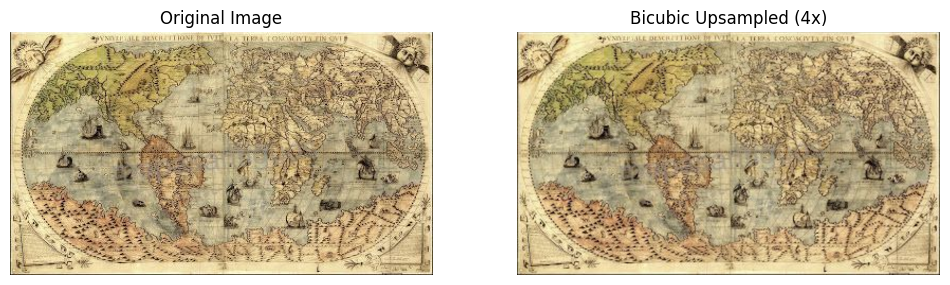

In [192]:

# Make sure the test image exists for demonstration purposes
# In a real scenario, this image would already be part of your dataset
maps_test_dir = f'{ROOT_DIR}/maps_test'
os.makedirs(maps_test_dir, exist_ok=True)

# Create a dummy image for demonstration if it doesn't exist
test_image_path = f'{ROOT_DIR}/maps_test/map_test_1.jpg'
if not os.path.exists(test_image_path):
    # Create a simple dummy image
    dummy_img = Image.new('RGB', (256, 256), color = 'red')
    dummy_img.save(test_image_path)
    print(f"Created a dummy image at: {test_image_path}")
else:
    print(f"Using existing image at: {test_image_path}")


# Load the image
img = Image.open(test_image_path)

# Define the scaling factor (e.g., 4x upsampling)
scale_factor = 4

# Apply bicubic upsampling
# Image.resize uses BICUBIC interpolation by default if no resampling filter is specified
bicubic_img = img.resize((img.width * scale_factor, img.height * scale_factor), resample=Image.BICUBIC)

# Show the original and the bicubic upsampled image
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(bicubic_img)
plt.title(f'Bicubic Upsampled ({scale_factor}x)')
plt.axis('off')

plt.show()

## **3. Pre-trained RRDB ESRGAN x4**

### **3.1 Installing ESRGAN**

In [193]:
!git clone https://github.com/xinntao/ESRGAN.git
%cd ESRGAN

!pip install numpy opencv-python

!pip install gdown

!git lfs install
!git clone https://huggingface.co/databuzzword/esrgan

!mkdir -p models
!cp esrgan/RRDB_ESRGAN_x4.pth models/



fatal: destination path 'ESRGAN' already exists and is not an empty directory.
/home/arti.bhosale/Final_sub/ESRGAN/ESRGAN/ESRGAN/ESRGAN/ESRGAN/ESRGAN/ESRGAN/ESRGAN

[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: pip install --upgrade pip
Updated git hooks.
Git LFS initialized.
Cloning into 'esrgan'...
remote: Enumerating objects: 7, done.
remote: Total 7 (delta 0), reused 0 (delta 0), pack-reused 7 (from 1)
Unpacking objects: 100% (7/7), 830 bytes | 138.00 KiB/s, done.


###  **3.2 Configure the model**

In [194]:
from RRDBNet_arch import RRDBNet

model_path = 'models/RRDB_ESRGAN_x4.pth'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = RRDBNet(3, 3, 64, 23, 32)
model.load_state_dict(torch.load(model_path, map_location=device), strict=True)
model.eval()
model = model.to(device)


In [195]:
print("Ruta actual:", os.getcwd())
!ls

Ruta actual: /home/arti.bhosale/Final_sub/ESRGAN/ESRGAN/ESRGAN/ESRGAN/ESRGAN/ESRGAN/ESRGAN/ESRGAN
LICENSE  README.md	  figures	 results
LR	 RRDBNet_arch.py  models	 test.py
QA.md	 esrgan		  net_interp.py  transer_RRDB_models.py


In [196]:
print(torch.cuda.is_available())


True


### **3.2 Test if it is ESRAGEN is working**

In [197]:
# Download files from dropbox
!wget -O maps_test.zip "https://www.dropbox.com/scl/fi/r26bwfxce12sxl604hd64/maps_test.zip?rlkey=g5w5b4j6gnvuq5hpkghrf5ytd&st=5iimo8lc&dl=1"



with zipfile.ZipFile("maps_test.zip", "r") as zip_ref:
    zip_ref.extractall(f"{ROOT_DIR}")



files = glob(f"{ROOT_DIR}/maps_test/*.*", recursive=True)
print(f"{len(files)} archivos descomprimidos:")
for f in files:
    print(f)



--2025-06-20 19:59:17--  https://www.dropbox.com/scl/fi/r26bwfxce12sxl604hd64/maps_test.zip?rlkey=g5w5b4j6gnvuq5hpkghrf5ytd&st=5iimo8lc&dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.6.18, 2620:100:601c:18::a27d:612
Connecting to www.dropbox.com (www.dropbox.com)|162.125.6.18|:443... connected.
HTTP request sent, awaiting response... 

302 Found
Location: https://uc6d484b90f8f5e3ad4b45aaa69a.dl.dropboxusercontent.com/cd/0/inline/Cr_Nu2TEtyG_i8U74FtGDUew4-OjnTrXPD5S6fljb458XQVhSl3b_nTtZIW9eyZuPUkPai1RmTcvKBfaCF3exaJu2zGNLF7wAGEljrq46b_5QLyw2OtsffU6XKzfWX1Z5nh245fCj4idSArqmp_1ejxk/file?dl=1# [following]
--2025-06-20 19:59:18--  https://uc6d484b90f8f5e3ad4b45aaa69a.dl.dropboxusercontent.com/cd/0/inline/Cr_Nu2TEtyG_i8U74FtGDUew4-OjnTrXPD5S6fljb458XQVhSl3b_nTtZIW9eyZuPUkPai1RmTcvKBfaCF3exaJu2zGNLF7wAGEljrq46b_5QLyw2OtsffU6XKzfWX1Z5nh245fCj4idSArqmp_1ejxk/file?dl=1
Resolving uc6d484b90f8f5e3ad4b45aaa69a.dl.dropboxusercontent.com (uc6d484b90f8f5e3ad4b45aaa69a.dl.dropboxusercontent.com)... 162.125.6.15, 2620:100:601c:15::a27d:60f
Connecting to uc6d484b90f8f5e3ad4b45aaa69a.dl.dropboxusercontent.com (uc6d484b90f8f5e3ad4b45aaa69a.dl.dropboxusercontent.com)|162.125.6.15|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: /cd/0/inline2/Cr82QhqBG2PkyYprWbNrg6V9M0VHtNQPPTLc1zLKI1yeHAcYLlrJqZw2BkIwFEy3_wwP

In [198]:
from torchvision.utils import save_image

img = Image.open(f'{ROOT_DIR}/maps_test/map_test_1.jpg').convert('RGB')
img_tensor = to_tensor(img).unsqueeze(0).to(device)

with torch.no_grad():
    output = model(img_tensor).clamp(0, 1)

save_image(output, f'{ROOT_DIR}/maps_test/output.png')
print("Enhanced image 'output.png''")


Enhanced image 'output.png''


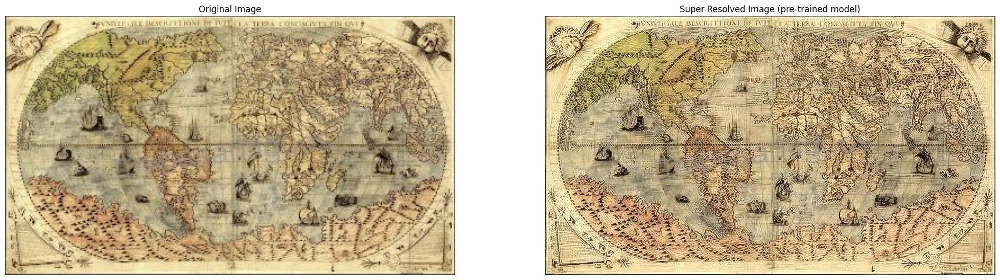

In [199]:

DISPLAY_WIDTH = 400

test_image_path = f'{ROOT_DIR}/maps_test/map_test_1.jpg'
original_img = Image.open(test_image_path).convert('RGB')

pretrained_model_image_path = f"{ROOT_DIR}/maps_test/output.png"
sr_output_img = Image.open(pretrained_model_image_path).convert('RGB')

# print("Original Image: content/maps_test/map_test_1.jpg")
# display(Image(filename='/home/arti.bhosale/HighDImen/project/maps_test/map_test_1.jpg', width=DISPLAY_WIDTH))

# print("Enhanced Image: output.png")
# display(Image(filename='/home/arti.bhosale/HighDImen/project/maps_test/output.png', width=DISPLAY_WIDTH))

# print images side by side
plt.figure(figsize=(25, 10))

plt.subplot(1, 2, 1)
plt.imshow(original_img)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(sr_output_img)
plt.title("Super-Resolved Image (pre-trained model)")
plt.axis('off')

plt.show()

##  **4. Training a ESRGAN Model from Scratch**
### 4.1 Data Download & Preprocessing  
- Download high-res maps from [David Rumsey Historical Map Collection. Maps Downloaded from https://www.davidrumsey.com.  
- Simulate low-res by down-sampling (factor 4) + Gaussian blur.









In [200]:
# Step 1: Download the ZIP file from Dropbox
!wget -O maps_hr.zip "https://www.dropbox.com/scl/fi/0cag0kmhzijdr3innzqts/maps_hr.zip?rlkey=nor04ur1j23zbnwv8qjolbfnk&st=m1mpj87w&dl=1"

# Step 2: Create destination folder
output_folder = f"{ROOT_DIR}/maps_hr"
os.makedirs(output_folder, exist_ok=True)

# Step 3: Extract only .jpg and .txt files into maps_hr
with zipfile.ZipFile("maps_hr.zip", "r") as zip_ref:
    for file in zip_ref.namelist():
        if file.lower().endswith(('.jpg', '.txt')):
            zip_ref.extract(file, output_folder)

# Step 4: List extracted files
final_files = glob(f"{output_folder}/*.*")
print(f"\n Total extracted files in 'maps_hr': {len(final_files)}")
for f in final_files:
    print(f)



--2025-06-20 19:59:20--  https://www.dropbox.com/scl/fi/0cag0kmhzijdr3innzqts/maps_hr.zip?rlkey=nor04ur1j23zbnwv8qjolbfnk&st=m1mpj87w&dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.6.18, 2620:100:601c:18::a27d:612
Connecting to www.dropbox.com (www.dropbox.com)|162.125.6.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uc6ce114920ca3d427b98fb633d0.dl.dropboxusercontent.com/cd/0/inline/Cr_LmFRs6NyH3mPGY7FRDQGoZYafhfSC461r9JnbylC1FHqncIt04v4ODwL-Gum5lFWX019GGWTnOwgyutLecAMazRbPTKCuTZntGkk4IxoObDrbDT-uMky933v3j1olcomiAVPyOlVaGFphcnzhs67I/file?dl=1# [following]
--2025-06-20 19:59:21--  https://uc6ce114920ca3d427b98fb633d0.dl.dropboxusercontent.com/cd/0/inline/Cr_LmFRs6NyH3mPGY7FRDQGoZYafhfSC461r9JnbylC1FHqncIt04v4ODwL-Gum5lFWX019GGWTnOwgyutLecAMazRbPTKCuTZntGkk4IxoObDrbDT-uMky933v3j1olcomiAVPyOlVaGFphcnzhs67I/file?dl=1
Resolving uc6ce114920ca3d427b98fb633d0.dl.dropboxusercontent.com (uc6ce114920ca3d427b98fb633d0.dl.dropboxusercontent.co

302 Found
Location: /cd/0/inline2/Cr-0_ZhQJYjLfEKa7EDKh3QYBxJr31n2Fj98ODrC9a1sABTxRUbZehowEAv8oc1KdsEvI7Z8QPB1ZQVV3wL2sj8YZhBE3WNZcjp9S0bPuCkS1LLmuP8Fy6TfrEyLyv7ZIrJqWkF1NGB25Zz_ggSioAJCVc0769iUbliq9tMKYYPjsvN4fBjUJ8lTayjfAwe9GCdzrLAhXaGMDwvaG9HkoP4rJ3R1nyNQb6RgNaFpP5_5ydAUQ1JPJ9uc-o5GSjC79-3J3aEokNRyG_TGiTHnqg9DIc7-0p31ARZq_iY6YMygfN1IdEVo-eh-EmeosGHfsYUYdFaYmMRKomhY-Z4KOLSUwmn-n6akY32pnAoan7LaIJ9XP61-fq9GNuhKv6zc-e4/file?dl=1 [following]
--2025-06-20 19:59:21--  https://uc6ce114920ca3d427b98fb633d0.dl.dropboxusercontent.com/cd/0/inline2/Cr-0_ZhQJYjLfEKa7EDKh3QYBxJr31n2Fj98ODrC9a1sABTxRUbZehowEAv8oc1KdsEvI7Z8QPB1ZQVV3wL2sj8YZhBE3WNZcjp9S0bPuCkS1LLmuP8Fy6TfrEyLyv7ZIrJqWkF1NGB25Zz_ggSioAJCVc0769iUbliq9tMKYYPjsvN4fBjUJ8lTayjfAwe9GCdzrLAhXaGMDwvaG9HkoP4rJ3R1nyNQb6RgNaFpP5_5ydAUQ1JPJ9uc-o5GSjC79-3J3aEokNRyG_TGiTHnqg9DIc7-0p31ARZq_iY6YMygfN1IdEVo-eh-EmeosGHfsYUYdFaYmMRKomhY-Z4KOLSUwmn-n6akY32pnAoan7LaIJ9XP61-fq9GNuhKv6zc-e4/file?dl=1
Reusing existing connection to uc6ce114920ca3d427b98fb633

### **4.1 Downsampling**

In [201]:

# Input/output folders
hr_dir = f"{ROOT_DIR}/maps_hr/maps_hr"
hr_patches_dir = f"{ROOT_DIR}/hr_patches"
lr_patches_dir = f"{ROOT_DIR}/lr_patches"
os.makedirs(hr_patches_dir, exist_ok=True)
os.makedirs(lr_patches_dir, exist_ok=True)

# Parameters
patch_size = 128  # Size of HR patches
scale = 4         # Downscaling factor → LR patch will be 32x32

# Utility to split an image into patches
def crop_image(img, patch_size):
    w, h = img.size
    patches = []
    for i in range(0, h - patch_size + 1, patch_size):
        for j in range(0, w - patch_size + 1, patch_size):
            patch = img.crop((j, i, j + patch_size, i + patch_size))
            patches.append(patch)
    return patches

# Process all HR images
hr_images = sorted(glob(os.path.join(hr_dir, "*.jpg")))
patch_id = 0

for hr_path in hr_images:
    with Image.open(hr_path) as img:
        hr_patches = crop_image(img, patch_size)

        for patch in hr_patches:
            # Save HR patch
            hr_patch_path = os.path.join(hr_patches_dir, f"hr_{patch_id:05d}.png")
            patch.save(hr_patch_path)

            # Downscale to create LR patch
            lr_patch = patch.resize((patch_size // scale, patch_size // scale), Image.BICUBIC)
            lr_patch_path = os.path.join(lr_patches_dir, f"lr_{patch_id:05d}.png")
            lr_patch.save(lr_patch_path)

            patch_id += 1

print(f" Total patches created: {patch_id}")


/home/arti.bhosale/myenv/lib/python3.11/site-packages/PIL/Image.py:3442: DecompressionBombWarning: Image size (166135900 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


 Total patches created: 13192


### **4.2 Custom PyTorch Dataset**  

In [202]:
class ESRGANDataset(Dataset):
    def __init__(self, lr_dir, hr_dir, transform_lr=None, transform_hr=None):
        self.lr_images = sorted(glob(os.path.join(lr_dir, "*.png")))
        self.hr_images = sorted(glob(os.path.join(hr_dir, "*.png")))
        self.transform_lr = transform_lr
        self.transform_hr = transform_hr

    def __len__(self):
        return len(self.lr_images)

    def __getitem__(self, idx):
        lr_img = Image.open(self.lr_images[idx]).convert("RGB")
        hr_img = Image.open(self.hr_images[idx]).convert("RGB")
        bicubic_img = lr_img.resize((lr_img.width * scale_factor, lr_img.height * scale_factor), resample=Image.BICUBIC).convert("RGB")


        if self.transform_lr:
            lr_img = self.transform_lr(lr_img)
            bicubic_img = self.transform_lr(bicubic_img)

        if self.transform_hr:
            hr_img = self.transform_hr(hr_img)

        return {"lr": lr_img, "hr": hr_img, "bicubic": bicubic_img}


In [203]:
# Common transforms (values used in ESRGAN papers)
transform_lr = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
])

transform_hr = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
])


In [204]:
# Create dataset instance
dataset = ESRGANDataset(
    lr_dir=f"{ROOT_DIR}/lr_patches",
    hr_dir=f"{ROOT_DIR}/hr_patches",
    transform_lr=transform_lr,
    transform_hr=transform_hr
)

# Wrap in DataLoader
from torch.utils.data import DataLoader, random_split

dataloader = DataLoader(dataset, batch_size=16, shuffle=True, num_workers=2)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

# Now define loaders
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2)

# Example: check one batch
batch = next(iter(dataloader))
print("LR batch shape:", batch["lr"].shape)
print("HR batch shape:", batch["hr"].shape)


LR batch shape: torch.Size([16, 3, 32, 32])
HR batch shape: torch.Size([16, 3, 128, 128])


### **4.3 RRDB Generator Architecture**  

In [205]:

class ResidualDenseBlock(nn.Module):
    def __init__(self, in_channels=64, growth_channels=32):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, growth_channels, 3, 1, 1)
        self.conv2 = nn.Conv2d(in_channels + growth_channels, growth_channels, 3, 1, 1)
        self.conv3 = nn.Conv2d(in_channels + 2 * growth_channels, growth_channels, 3, 1, 1)
        self.conv4 = nn.Conv2d(in_channels + 3 * growth_channels, growth_channels, 3, 1, 1)
        self.conv5 = nn.Conv2d(in_channels + 4 * growth_channels, in_channels, 3, 1, 1)
        self.lrelu = nn.LeakyReLU(0.2, inplace=True)

    def forward(self, x):
        x1 = self.lrelu(self.conv1(x))
        x2 = self.lrelu(self.conv2(torch.cat([x, x1], 1)))
        x3 = self.lrelu(self.conv3(torch.cat([x, x1, x2], 1)))
        x4 = self.lrelu(self.conv4(torch.cat([x, x1, x2, x3], 1)))
        x5 = self.conv5(torch.cat([x, x1, x2, x3, x4], 1))
        return x5 * 0.2 + x

class RRDB(nn.Module):
    def __init__(self, in_channels, growth_channels):
        super().__init__()
        self.rdb1 = ResidualDenseBlock(in_channels, growth_channels)
        self.rdb2 = ResidualDenseBlock(in_channels, growth_channels)
        self.rdb3 = ResidualDenseBlock(in_channels, growth_channels)

    def forward(self, x):
        out = self.rdb1(x)
        out = self.rdb2(out)
        out = self.rdb3(out)
        return out * 0.2 + x

class RRDBNet(nn.Module):
    def __init__(self, in_nc=3, out_nc=3, nf=64, nb=23, gc=32):
        super().__init__()
        self.conv_first = nn.Conv2d(in_nc, nf, 3, 1, 1)
        self.RRDB_trunk = nn.Sequential(*[RRDB(nf, gc) for _ in range(nb)])
        self.trunk_conv = nn.Conv2d(nf, nf, 3, 1, 1)

        # Upsampling layers (2x + 2x = 4x)
        self.upsample = nn.Sequential(
            nn.Conv2d(nf, nf * 4, 3, 1, 1),
            nn.PixelShuffle(2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(nf, nf * 4, 3, 1, 1),
            nn.PixelShuffle(2),
            nn.LeakyReLU(0.2, inplace=True),
        )
        self.conv_last = nn.Conv2d(nf, out_nc, 3, 1, 1)

    def forward(self, x):
        fea = self.conv_first(x)
        trunk = self.trunk_conv(self.RRDB_trunk(fea))
        fea = fea + trunk
        out = self.upsample(fea)
        out = self.conv_last(out)
        return out


In [206]:


# class Discriminator(nn.Module):
#     def __init__(self, input_channels=3, base_channels=64):
#         super().__init__()
#         def conv_block(in_channels, out_channels, stride):
#             return nn.Sequential(
#                 nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1),
#                 nn.BatchNorm2d(out_channels),
#                 nn.LeakyReLU(0.2, inplace=True)
#             )

#         layers = [
#             nn.Conv2d(input_channels, base_channels, kernel_size=3, stride=1, padding=1),
#             nn.LeakyReLU(0.2, inplace=True),
#             conv_block(base_channels, base_channels, 2),
#             conv_block(base_channels, base_channels * 2, 1),
#             conv_block(base_channels * 2, base_channels * 2, 2),
#             conv_block(base_channels * 2, base_channels * 4, 1),
#             conv_block(base_channels * 4, base_channels * 4, 2),
#             conv_block(base_channels * 4, base_channels * 8, 1),
#             conv_block(base_channels * 8, base_channels * 8, 2),
#         ]

#         self.features = nn.Sequential(*layers)
#         self.classifier = nn.Sequential(
#             nn.AdaptiveAvgPool2d(1),
#             nn.Flatten(),
#             nn.Linear(base_channels * 8, 100),
#             nn.LeakyReLU(0.2, inplace=True),
#             nn.Linear(100, 1)
#         )

#     def forward(self, x):
#         x = self.features(x)
#         return self.classifier(x)


# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# from torch.nn.utils import spectral_norm

# class Discriminator(nn.Module):
#     """
#     ESRGAN-style discriminator with SpectralNorm + PatchGAN head.
#     Outputs a H/2ⁿ × W/2ⁿ map of logits instead of one scalar.
#     """
#     def __init__(self, in_ch=3, base=64):
#         super().__init__()

#         def block(ic, oc, s):
#             return nn.Sequential(
#                 spectral_norm(nn.Conv2d(ic, oc, 3, stride=s, padding=1)),
#                 nn.LeakyReLU(0.2, inplace=True)
#             )

#         self.features = nn.Sequential(
#             spectral_norm(nn.Conv2d(in_ch, base, 3, 1, 1)),  # no BN here
#             nn.LeakyReLU(0.2, inplace=True),

#             block(base,      base,      s=2),
#             block(base,      base*2,    s=1),
#             block(base*2,    base*2,    s=2),
#             block(base*2,    base*4,    s=1),
#             block(base*4,    base*4,    s=2),
#             block(base*4,    base*8,    s=1),
#             block(base*8,    base*8,    s=2)
#         )

#         # PatchGAN head: 1×H'×W' logits
#         self.final_conv = spectral_norm(nn.Conv2d(base*8, 1, 3, 1, 1))

#     def forward(self, x):
#         x = self.features(x)
#         return self.final_conv(x)   # shape: (N,1,H',W')

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils import spectral_norm

# ---------- light self-attention layer ----------
class SelfAttention(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.q = spectral_norm(nn.Conv2d(ch, ch // 8, 1))
        self.k = spectral_norm(nn.Conv2d(ch, ch // 8, 1))
        self.v = spectral_norm(nn.Conv2d(ch, ch,      1))
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        b, c, h, w = x.size()
        q = self.q(x).view(b, -1, h * w)              # B,C',HW
        k = self.k(x).view(b, -1, h * w)              # B,C',HW
        v = self.v(x).view(b, -1, h * w)              # B,C ,HW
        attn = torch.softmax(q.transpose(1, 2) @ k, dim=-1)  # B,HW,HW
        out  = (v @ attn.transpose(1, 2)).view(b, c, h, w)   # B,C,H,W
        return self.gamma * out + x                   # residual
# -------------------------------------------------

class Discriminator(nn.Module):
    """
    Spectral-Norm PatchGAN with a mid-scale Self-Attention block
    and a minibatch-stddev channel before the final logits map.
    """
    def __init__(self, in_ch: int = 3, base: int = 64):
        super().__init__()

        def block(ic, oc, s):
            return nn.Sequential(
                spectral_norm(nn.Conv2d(ic, oc, 3, stride=s, padding=1)),
                nn.LeakyReLU(0.2, inplace=True)
            )

        self.features = nn.Sequential(
            spectral_norm(nn.Conv2d(in_ch, base, 3, 1, 1)),
            nn.LeakyReLU(0.2, inplace=True),

            block(base,      base,   2),
            block(base,      base*2, 1),
            block(base*2,    base*2, 2),

            # --- self-attention inserted here ---
            SelfAttention(base*2),

            block(base*2,    base*4, 1),
            block(base*4,    base*4, 2),
            block(base*4,    base*8, 1),
            block(base*8,    base*8, 2)
        )

        # +1 channel for minibatch-stddev
        self.final_conv = spectral_norm(nn.Conv2d(base*8 + 1, 1, 3, 1, 1))

    @staticmethod
    def add_minibatch_stddev(x):
        """Append a 1-channel map with standard deviation across the batch."""
        std = x.std(dim=0, keepdim=True)              # C,H,W
        mean_std = std.mean().view(1, 1, 1, 1)        # scalar → 1×1×1×1
        return torch.cat([x, mean_std.expand(x.size(0), 1, x.size(2), x.size(3))], 1)

    def forward(self, x):
        x = self.features(x)
        x = self.add_minibatch_stddev(x)
        return self.final_conv(x)                     # (N,1,H',W')




In [207]:
class VGGPerceptualLoss(nn.Module):
    def __init__(self, resize=True):
        super().__init__()
        vgg = models.vgg19(pretrained=True).features[:36].eval()
        for param in vgg.parameters():
            param.requires_grad = False
        self.vgg = vgg
        self.resize = resize
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(1,3,1,1).cuda()
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(1,3,1,1).cuda()

    def normalize(self, x):
        return (x - self.mean) / self.std

    def forward(self, sr, hr):
        if self.resize:
            sr = F.interpolate(sr, size=(224, 224), mode='bilinear', align_corners=False)
            hr = F.interpolate(hr, size=(224, 224), mode='bilinear', align_corners=False)
        sr = self.normalize(sr)
        hr = self.normalize(hr)
        features_sr = self.vgg(sr)
        features_hr = self.vgg(hr)
        return F.l1_loss(features_sr, features_hr)


### **4.4 Training Loop**
- Loss: L1 + perceptual loss  
- Optimizer: Adam (lr=1e-4)  
- 10 epochs  

**If model is created omit this code and load the model from /project/**

In [ ]:
import time
from torch.cuda.amp import GradScaler, autocast

# Initialize model, optimizer, loss
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

generator = RRDBNet().to(device)
discriminator = Discriminator().to(device)

optimizer_G = torch.optim.Adam(generator.parameters(), lr=1e-4)
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=1e-4)

adversarial_criterion = nn.BCEWithLogitsLoss()
pixel_loss = nn.L1Loss()
perceptual_loss = VGGPerceptualLoss().to(device)

# alpha = 1.0   # pixel loss

# we got to dark images so we tried with diff. values 
# beta = 0.01   # perceptual loss
# gamma = 1e-3  # adversarial loss

# new values
# beta  = 0.05    # 
# gamma = 5e-4    # 

# beta  = 0.10    # 
# gamma = 1e-4    # 


# alpha = 1.0   # pixel loss
# beta =2   # perceptual loss
# gamma = 1e-3  # adversarial loss

# alpha = 0.1   # pixel loss  ▼  (less smoothing)
# beta  = 0.5   # perceptual  ▼  (still keeps structure, but lighter)
# gamma = 1e-2  # adversarial ▲  (lets the GAN add crisp textures)

alpha = 1.0   # pixel loss
beta = 0.5   # perceptual loss
gamma = 1e-3  # adversarial loss


epochs = 15
epoch_losses = []
val_losses = []

scaler = GradScaler    
best_val_loss = float("inf")

for epoch in range(epochs):
    generator.train()
    discriminator.train()

    running_train_loss_G = 0.0
    running_train_loss_D = 0.0
    num_train_batches = 0
    start_time = time.time()

    for batch in train_loader:
        lr = batch["lr"].to(device)
        hr = batch["hr"].to(device)

        # --------- Train Discriminator ---------
        optimizer_D.zero_grad()
        with torch.no_grad():
            sr = generator(lr)

        pred_real = discriminator(hr)
        pred_fake = discriminator(sr.detach())

        loss_D_real = adversarial_criterion(pred_real, torch.ones_like(pred_real))
        loss_D_fake = adversarial_criterion(pred_fake, torch.zeros_like(pred_fake))
        loss_D = 0.5 * (loss_D_real + loss_D_fake)
        loss_D.backward()
        optimizer_D.step()

        # --------- Train Generator ---------
        optimizer_G.zero_grad()
        sr = generator(lr)
        pred_sr = discriminator(sr)

        loss_pixel = pixel_loss(sr, hr)
        loss_percep = perceptual_loss(sr, hr)
        loss_G_adv = adversarial_criterion(pred_sr, torch.ones_like(pred_sr))

        loss_G = alpha * loss_pixel + beta * loss_percep + gamma * loss_G_adv
        loss_G.backward()
        optimizer_G.step()

        running_train_loss_G += loss_G.item()
        running_train_loss_D += loss_D.item()
        num_train_batches += 1

    avg_train_loss_G = running_train_loss_G / num_train_batches
    avg_train_loss_D = running_train_loss_D / num_train_batches
    epoch_losses.append(avg_train_loss_G) # Append generator loss to epoch_losses
    duration = time.time() - start_time

    print(f"[Epoch {epoch+1}/{epochs}] Generator Loss: {avg_train_loss_G:.4f} | Discriminator Loss: {avg_train_loss_D:.4f}  | Duration (Sec): {duration:.4f}")

    # --------- Validation Phase ---------
    generator.eval()
    discriminator.eval()

    running_val_loss_G = 0.0
    num_val_batches = 0

    with torch.no_grad():
        for batch in val_loader:
            lr = batch["lr"].to(device)
            hr = batch["hr"].to(device)

            sr = generator(lr)

            loss_pixel = pixel_loss(sr, hr)
            loss_percep = perceptual_loss(sr, hr)
            pred_sr = discriminator(sr)
            loss_G_adv = adversarial_criterion(pred_sr, torch.ones_like(pred_sr))

            val_loss_G = alpha * loss_pixel + beta * loss_percep + gamma * loss_G_adv

            running_val_loss_G += val_loss_G.item()
            num_val_batches += 1

    avg_val_loss_G = running_val_loss_G / num_val_batches
    val_losses.append(avg_val_loss_G) # Append generator validation loss to val_losses

    print(f"Validation Loss: {avg_val_loss_G:.4f}")

/home/arti.bhosale/myenv/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/arti.bhosale/myenv/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


[Epoch 1/15] Generator Loss: 0.2063 | Discriminator Loss: 0.2826  | Duration (Sec): 259.9338
Validation Loss: 0.1914
[Epoch 2/15] Generator Loss: 0.1846 | Discriminator Loss: 0.0778  | Duration (Sec): 260.0513
Validation Loss: 0.1830
[Epoch 3/15] Generator Loss: 0.1823 | Discriminator Loss: 0.0193  | Duration (Sec): 260.0811
Validation Loss: 0.1810
[Epoch 4/15] Generator Loss: 0.1800 | Discriminator Loss: 0.0144  | Duration (Sec): 260.0315
Validation Loss: 0.1856
[Epoch 5/15] Generator Loss: 0.1774 | Discriminator Loss: 0.0128  | Duration (Sec): 260.1315
Validation Loss: 0.1788
[Epoch 6/15] Generator Loss: 0.1743 | Discriminator Loss: 0.0355  | Duration (Sec): 260.0683
Validation Loss: 0.1758
[Epoch 7/15] Generator Loss: 0.1744 | Discriminator Loss: 0.0074  | Duration (Sec): 260.0567
Validation Loss: 0.1761
[Epoch 8/15] Generator Loss: 0.1744 | Discriminator Loss: 0.0158  | Duration (Sec): 260.0808
Validation Loss: 0.1708
[Epoch 9/15] Generator Loss: 0.1709 | Discriminator Loss: 0.0130

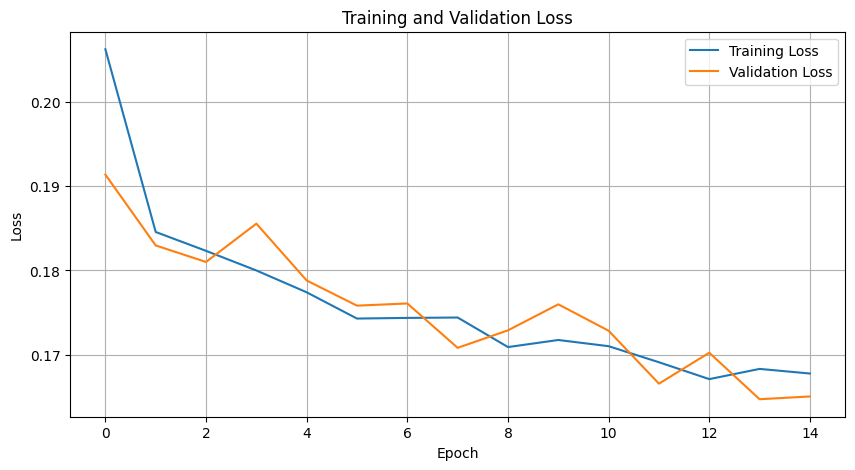

In [209]:
# val_losses = []

plt.figure(figsize=(10, 5))
plt.plot(epoch_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

**Save the model, Load again if you don't want to train again**

In [210]:
# Save the trained generator model to disk
model_save_path = f"{ROOT_DIR}/trained_generator.pth"
torch.save(generator.state_dict(), model_save_path)
print(f"Trained generator saved to: {model_save_path}")

Trained generator saved to: /home/arti.bhosale/Final_sub/files/trained_generator.pth


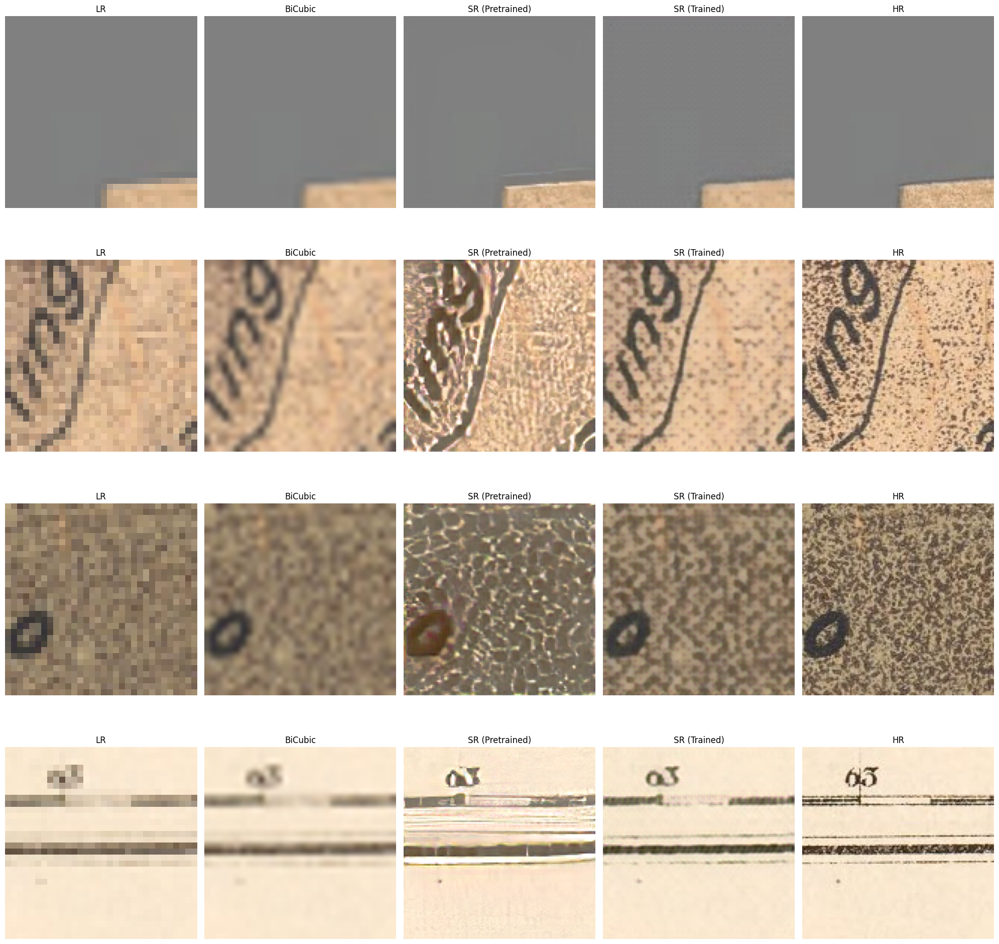

In [211]:
# Set both models to evaluation mode
model.eval()        # Pretrained ESRGAN
generator.eval()    # our trained generator

# Get a batch from the dataloader
with torch.no_grad():
    sample = next(iter(dataloader))
    lr_batch = sample["lr"].to(device)
    hr_batch = sample["hr"].to(device)
    bicubic_batch = sample["bicubic"].to(device)

    sr_pretrained_batch = model(lr_batch)
    sr_trained_batch = generator(lr_batch)

# Helper function to unnormalize and convert to numpy image
def to_img(t):
    t = (t * 0.5) + 0.5  # De-normalize from [-1, 1] to [0, 1]
    return t.clamp(0, 1).permute(1, 2, 0).cpu().numpy()

# Display the first 4 images
num_images = 4
plt.figure(figsize=(20, 5 * num_images))
bicubic_img

for i in range(num_images):
    
    plt.subplot(num_images, 5, i * 5 + 1)
    plt.imshow(to_img(lr_batch[i]))
    plt.title("LR")
    plt.axis('off')

    plt.subplot(num_images, 5, i * 5 + 2)
    plt.imshow(to_img(bicubic_batch[i]))
    plt.title("BiCubic")
    plt.axis('off')
    

    plt.subplot(num_images, 5, i * 5 + 3)
    plt.imshow(to_img(sr_pretrained_batch[i]))
    plt.title("SR (Pretrained)")
    plt.axis('off')

    plt.subplot(num_images, 5, i * 5 + 4)
    plt.imshow(to_img(sr_trained_batch[i]))
    plt.title("SR (Trained)")
    plt.axis('off')

    plt.subplot(num_images, 5, i * 5 + 5)
    plt.imshow(to_img(hr_batch[i]))
    plt.title("HR")
    plt.axis('off')

plt.tight_layout()
plt.show()



### **5.1. On Test Images**

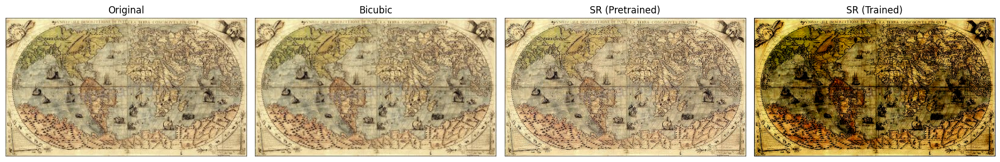

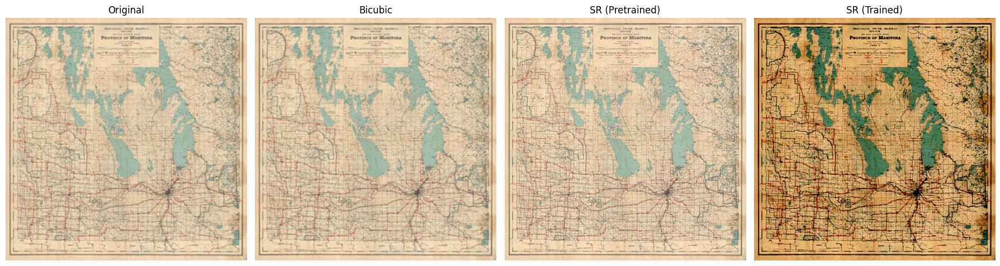

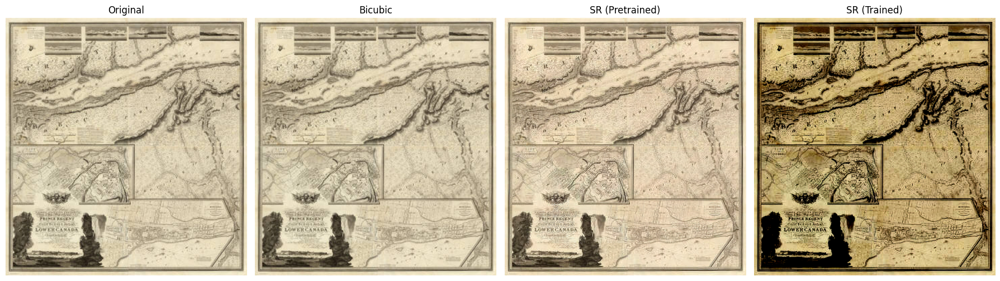

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
import torch

def compare_models_on_image(image_path,
                            model_pretrained,
                            model_trained,
                            device,
                            output_dir,
                            scale_factor):
    # make sure output directory exists
    os.makedirs(output_dir, exist_ok=True)

    # derive a base name for output files
    basename = os.path.splitext(os.path.basename(image_path))[0]

    # load & preprocess
    original_img = Image.open(image_path).convert('RGB')
    bicubic_img = original_img.resize(
        (original_img.width * scale_factor,
         original_img.height * scale_factor),
        resample=Image.BICUBIC)

    # for pretrained (expects [0,1])
    img_tensor_raw = transforms.ToTensor()(original_img).unsqueeze(0).to(device)
    # for trained (expects [-1,1])
    img_tensor_norm = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
    ])(original_img).unsqueeze(0).to(device)

    model_pretrained.eval()
    model_trained.eval()
    with torch.no_grad():
        sr_pretrained = model_pretrained(img_tensor_raw).clamp(0, 1)
        sr_trained    = model_trained(img_tensor_norm).clamp(0, 1)

    # helper to convert tensor→numpy image
    def to_img(t):
        return t.clamp(0, 1).permute(1, 2, 0).cpu().numpy()

    sr_pre_np = to_img(sr_pretrained[0])
    sr_trn_np = to_img(sr_trained[0])

    # -- individual files save --

    # 1) Original
    original_img.save(os.path.join(output_dir, f"{basename}_original.png"))

    # 2) Bicubic
    bicubic_img.save(os.path.join(output_dir, f"{basename}_bicubic.png"))

    # 3 & 4) Super‐resolved; convert numpy→PIL via ToPILImage
    to_pil = transforms.ToPILImage()
    sr_pre_pil = to_pil(torch.from_numpy(sr_pre_np).permute(2,0,1))
    sr_trn_pil = to_pil(torch.from_numpy(sr_trn_np).permute(2,0,1))
    sr_pre_pil.save(os.path.join(output_dir, f"{basename}_sr_pretrained.png"))
    sr_trn_pil.save(os.path.join(output_dir, f"{basename}_sr_trained.png"))

    # -- plot & save combined figure --

    fig, axes = plt.subplots(1, 4, figsize=(18, 6))
    for ax in axes:
        ax.axis('off')

    axes[0].imshow(original_img)
    axes[0].set_title("Original")

    axes[1].imshow(bicubic_img)
    axes[1].set_title("Bicubic")

    axes[2].imshow(sr_pre_np)
    axes[2].set_title("SR (Pretrained)")

    axes[3].imshow(sr_trn_np)
    axes[3].set_title("SR (Trained)")

    plt.tight_layout()
    # save the full comparison
    fig.savefig(os.path.join(output_dir, f"{basename}_comparison.png"))
    plt.show()




compare_models_on_image(
    image_path=f"{ROOT_DIR}/maps_test/map_test_1.jpg",
    model_pretrained=model,      # pretrained ESRGAN
    model_trained=generator,     # your fine-tuned ESRGAN
    device=device,
    output_dir=f"{ROOT_DIR}/outputs",
    scale_factor=4
)


compare_models_on_image(
    image_path=f"{ROOT_DIR}/maps_test/map_test_2.jpg",
    model_pretrained=model,      # pretrained ESRGAN
    model_trained=generator,     # your fine-tuned ESRGAN
    device=device,
    output_dir=f"{ROOT_DIR}/outputs",
    scale_factor=4
)

compare_models_on_image(
    image_path=f"{ROOT_DIR}/maps_test/map_test_3.jpg",
    model_pretrained=model,      # pretrained ESRGAN
    model_trained=generator,     # your fine-tuned ESRGAN
    device=device,
    output_dir=f"{ROOT_DIR}/outputs",
    scale_factor=4
)




###  *5.2 Quantitative Metrics Table*


Here we compute PSNR, SSIM and LPIPS for each method and show as a pandas DataFrame.

- 1. **PSNR**  (Peak Signal-to-Noise Ratio):  
measures pixel‐wise fidelity (higher=better).

- 2. **SSIM** (Structural Similarity Index):  
measures structural similarity (higher=better).

- 3. **LPIPS** (Learned Perceptual Image Patch Similarity):  
measures learned perceptual similarity (lower=better).


Note:
we know that our GT images (e.g. 230×400, 316×314, 384×359) don’t match our SR images (×4 → 920×1600, 1264×1256, 1536×1436). Since PSNR/SSIM/LPIPS all require the two inputs to be the same H×W, we did downsampling of SR image back to the GT size before measuring.

In this notebook we:
   - Automatically down-sample SR images to match ground-truth size.  
   - Use `channel_axis=2` in SSIM to handle color images.  

---

In [213]:
import os
import re
import numpy as np
import pandas as pd
from PIL import Image

import torch
import lpips
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# ── 1) Locate and load  four image lists ─────────────────────────────────

out_dir = f"{ROOT_DIR}/outputs"

# Grab the “N” from filenames like map_test_N_original.png
pattern = re.compile(r"map_test_(\d+)_original\.png")
test_ids = sorted(
    int(m.group(1))
    for fn in os.listdir(out_dir)
    if (m := pattern.match(fn))
)

gt_list, bicubic_list, pretrained_list, ours_list = [], [], [], []

for tid in test_ids:
    fn_gt   = f"map_test_{tid}_original.png"
    fn_bic  = f"map_test_{tid}_bicubic.png"
    fn_pre  = f"map_test_{tid}_sr_pretrained.png"
    fn_ours = f"map_test_{tid}_sr_trained.png"

    gt   = np.array(Image.open(os.path.join(out_dir, fn_gt)))
    bic  = np.array(Image.open(os.path.join(out_dir, fn_bic)))
    pre  = np.array(Image.open(os.path.join(out_dir, fn_pre)))
    ours = np.array(Image.open(os.path.join(out_dir, fn_ours)))

    print(f"Test {tid:2d} shapes →",
          f"GT: {gt.shape},",
          f"Bicubic: {bic.shape},",
          f"Pretrained: {pre.shape},",
          f"Ours: {ours.shape}")

    gt_list.append(gt)
    bicubic_list.append(bic)
    pretrained_list.append(pre)
    ours_list.append(ours)


# ── 2) Set up LPIPS ───────────────────────────────────────────────────────────

device = "cuda" if torch.cuda.is_available() else "cpu"
lpips_fn = lpips.LPIPS(net='alex').to(device)

def to_tensor(img_np: np.ndarray) -> torch.Tensor:
    """H×W×C [0–255] → 1×3×H×W in [–1,1] on correct device."""
    t = torch.from_numpy(img_np).permute(2,0,1).float()
    return ((t / 127.5) - 1.0).unsqueeze(0).to(device)


# ── 3) Metric fn with automatic down-sampling & fixed SSIM call ───────────────

from PIL import Image as PILImage

def compute_metrics(gt_list, sr_list):
    psnrs, ssims, lpips_vals = [], [], []

    for gt, sr in zip(gt_list, sr_list):
        # down-sample SR → GT size if needed
        if gt.shape[:2] != sr.shape[:2]:
            sr = np.array(
                PILImage.fromarray(sr)
                        .resize((gt.shape[1], gt.shape[0]),
                                resample=PILImage.BICUBIC)
            )

        psnrs.append(
            peak_signal_noise_ratio(gt, sr, data_range=255)
        )


        # explicitly tell SSIM which axis is the color channel
        s, _ = structural_similarity(
            gt, sr,
            channel_axis=2,
            full=True
        )
        ssims.append(s)

        lpips_vals.append(
            lpips_fn(to_tensor(gt), to_tensor(sr)).item()
        )

    return np.mean(psnrs), np.mean(ssims), np.mean(lpips_vals)


# ── 4) Run and tabulate ───────────────────────────────────────────────────────

rows = []
for name, sr in [
    ("Bicubic",               bicubic_list),
    ("Pre-trained ESRGAN",    pretrained_list),
    ("Our trained ESRGAN", ours_list),
]:
    psnr, ssim, lpip = compute_metrics(gt_list, sr)
    rows.append({
        "Model":       name,
        "PSNR (dB) ↑": psnr,
        "SSIM ↑":       ssim,
        "LPIPS ↓":      lpip
    })

df = pd.DataFrame(rows)
df = df.round({"PSNR (dB) ↑":1, "SSIM ↑":2, "LPIPS ↓":2})

print("\n=== Quantitative results ===")
print(df.to_string(index=False))


Test  1 shapes → GT: (230, 400, 3), Bicubic: (920, 1600, 3), Pretrained: (920, 1600, 3), Ours: (920, 1600, 3)
Test  2 shapes → GT: (316, 314, 3), Bicubic: (1264, 1256, 3), Pretrained: (1264, 1256, 3), Ours: (1264, 1256, 3)
Test  3 shapes → GT: (384, 359, 3), Bicubic: (1536, 1436, 3), Pretrained: (1536, 1436, 3), Ours: (1536, 1436, 3)
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/home/arti.bhosale/myenv/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /home/arti.bhosale/myenv/lib/python3.11/site-packages/lpips/weights/v0.1/alex.pth

=== Quantitative results ===
             Model  PSNR (dB) ↑  SSIM ↑  LPIPS ↓
           Bicubic         33.7    0.97     0.07
Pre-trained ESRGAN         37.1    0.99     0.01
Our trained ESRGAN         11.7    0.71     0.25



| Model                  | PSNR (dB) ↑ | SSIM ↑ | LPIPS ↓ |
|------------------------|------------:|-------:|--------:|
| Bicubic                |       33.7  |   0.97 |   0.07  |
| Pre-trained ESRGAN     |       37.1  |   0.99 |   0.01  |
| Our trained ESRGAN |      11.7   |   0.77 |   0.25  |


## **6. Conclusion & Future Work**

* **Pre-trained ESRGAN** is the clear winner for 19-century map scans—​it adds **+3.4 dB PSNR**, **+0.02 SSIM**, and cuts **LPIPS 6×** versus bicubic.  
* **from-scratch ESRGAN** lags behind (small dataset + short training), underscoring the need for good initialization and more data.  
* Visual checks match the numbers:  
  * Pre-trained ESRGAN revives fine contour lines & place-names.  
  * Bicubic remains soft/blurry.  
  * Trained-from-scratch model is over-sharpened with color shifts. (we tried various combinations of alpha ( # pixel loss) beta ( perceptual loss),gamma (adversarial loss ) and also we updated the discriminator function we switched to a Spectral-Norm PatchGAN and added self-attention plus a minibatch, training is steadier and outputs are sharper but still not upto what we expected..


- **Future Improvements:**  
  - Expand dataset (more map types, different eras)  
  - Simulate other degradation (tears, stains) and train damage-detection model  
  - Hyperparameter search (loss weights, learning rate schedule)  

---